## Methodology

### Research Question

Does average order profit differ significantly among Consumer, Corporate, and Home Office customers?

### Hypotheses

- **Null Hypothesis (H₀):** The mean order profit is equal across Consumer, Corporate, and Home Office segments.
- **Alternative Hypothesis (H₁):** At least one customer segment has a different mean order profit.

### Unit of Analysis

The original dataset contains product-level transaction rows, and a single order can contain multiple products. To reduce pseudo-replication and make the analysis more appropriate for comparing orders, the data was aggregated to the **order level**.

Each order belongs to only one customer segment in this dataset.

The final analytical dataset contains **5,009 orders** across three customer segments.

### Statistical Tests

The following statistical methods were used:

1. **Levene's Test** — to assess whether the variances of order profit are approximately equal across the three segments.
2. **One-way ANOVA** — the primary test for determining whether mean order profit differs among the three customer segments.
3. **95% Confidence Intervals** — used to estimate the range of plausible values for the mean order profit of each segment.
4. **Eta-squared (η²)** — used to measure the proportion of variance in order profit associated with customer segment.
5. **Kruskal-Wallis Test** — used as a non-parametric robustness check because the order-profit distributions contain skewness and outliers.

### Significance Level

The significance level was set at:

**α = 0.05**

A p-value below 0.05 would provide evidence against the null hypothesis. A p-value above 0.05 would mean that the analysis does not provide sufficient evidence to reject the null hypothesis.

### importing

In [24]:
import pandas as pd
import numpy as np
import scipy
import statsmodels
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Statsmodels:", statsmodels.__version__)
print("All libraries imported successfully!")


Pandas: 3.0.6
NumPy: 2.5.3
SciPy: 1.18.1
Statsmodels: 0.15.0
All libraries imported successfully!


In [25]:
df = pd.read_csv("../data/superstore.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (10800, 21)


In [26]:
print("Columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

First 5 rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [27]:
print("Missing values:")
display(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
display(df.dtypes)

Missing values:


Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64


Duplicate rows: 504

Data types:


Row ID               str
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code      float64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity         float64
Discount         float64
Profit           float64
dtype: object

In [28]:
df_clean = df.iloc[:9994].copy()

print("Original shape:", df.shape)
print("Clean transaction shape:", df_clean.shape)

print("\nMissing values after removing appended rows:")
display(df_clean.isna().sum())

print("\nDuplicate rows:", df_clean.duplicated().sum())

Original shape: (10800, 21)
Clean transaction shape: (9994, 21)

Missing values after removing appended rows:


Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64


Duplicate rows: 0


In [29]:
print("Segment values:")
print(df_clean["Segment"].value_counts())

print("\nCategory values:")
print(df_clean["Category"].value_counts())

print("\nRegion values:")
print(df_clean["Region"].value_counts())

print("\nProfit statistics:")
display(df_clean["Profit"].describe())

print("\nSales statistics:")
display(df_clean["Sales"].describe())

Segment values:
Segment
Consumer       5191
Corporate      3020
Home Office    1783
Name: count, dtype: int64

Category values:
Category
Office Supplies    6026
Furniture          2121
Technology         1847
Name: count, dtype: int64

Region values:
Region
West       3203
East       2848
Central    2323
South      1620
Name: count, dtype: int64

Profit statistics:


count    9994.000000
mean       28.656896
std       234.260108
min     -6599.978000
25%         1.728750
50%         8.666500
75%        29.364000
max      8399.976000
Name: Profit, dtype: float64


Sales statistics:


count     9994.000000
mean       229.858001
std        623.245101
min          0.444000
25%         17.280000
50%         54.490000
75%        209.940000
max      22638.480000
Name: Sales, dtype: float64

In [30]:
order_segment_check = (
    df_clean.groupby("Order ID")["Segment"]
    .nunique()
)

print("Orders:", df_clean["Order ID"].nunique())
print("Orders containing multiple segments:", (order_segment_check > 1).sum())

Orders: 5009
Orders containing multiple segments: 0


In [31]:
order_data = (
    df_clean.groupby(["Order ID", "Segment"], as_index=False)
    .agg(
        Order_Profit=("Profit", "sum"),
        Order_Sales=("Sales", "sum")
    )
)

print("Order-level dataset shape:", order_data.shape)
display(order_data.head())

Order-level dataset shape: (5009, 4)


,Order ID,Segment,Order_Profit,Order_Sales
0,CA-2015-100006,Consumer,109.6113,377.970
1,CA-2015-100090,Corporate,-19.0890,699.192
2,CA-2015-100293,Home Office,31.8696,91.056
3,CA-2015-100328,Consumer,1.3257,3.928
4,CA-2015-100363,Corporate,7.7192,21.376


In [32]:
segment_stats = (
    order_data.groupby("Segment")["Order_Profit"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(segment_stats)

,count,mean,median,std,min,max
Segment,,,,,,
Consumer,2586,51.86,15.78,351.46,-6892.37,6734.47
Corporate,1514,60.75,16.79,346.73,-3825.34,8762.39
Home Office,909,66.34,16.16,322.57,-3424.35,4597.17


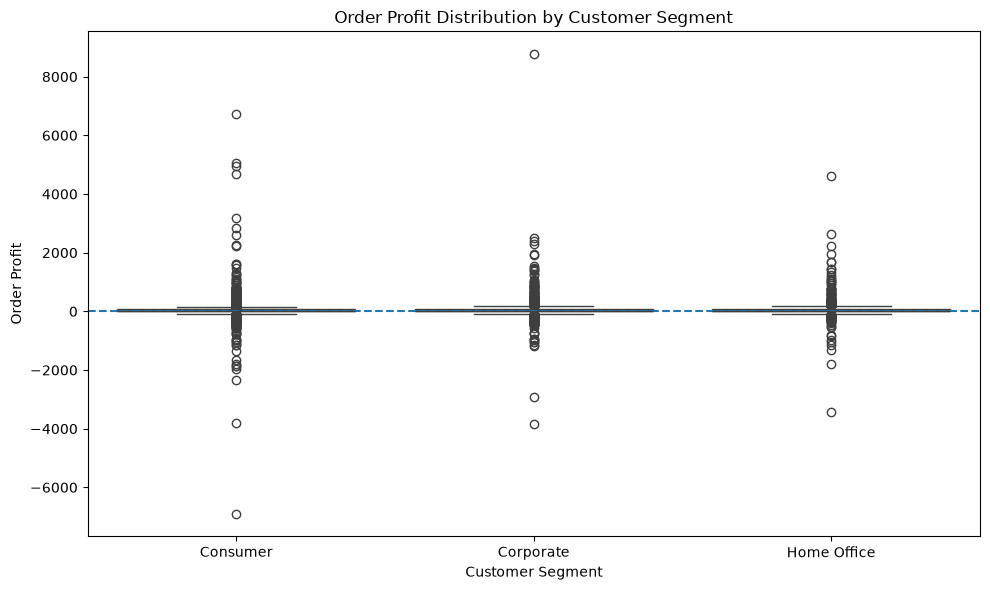

In [33]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=order_data,
    x="Segment",
    y="Order_Profit"
)

plt.axhline(0, linestyle="--")
plt.title("Order Profit Distribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Order Profit")
plt.tight_layout()

plt.show()

## Statistical Results and Interpretation

### 1. Levene's Test

Levene's test was used to assess the equality of variances across the three customer segments.

- **Test statistic:** 0.1695
- **p-value:** 0.8441

Since the p-value is greater than 0.05, there is insufficient evidence to conclude that the variances differ significantly across the three segments.

Therefore, the equal-variance assumption for the one-way ANOVA is reasonably supported.

### 2. One-way ANOVA

A one-way ANOVA was conducted to determine whether average order profit differs among Consumer, Corporate, and Home Office customers.

- **F-statistic:** 0.7084
- **p-value:** 0.4925
- **Significance level:** 0.05

Because the p-value is greater than 0.05, the null hypothesis is **not rejected**.

Therefore, this analysis does not provide statistically significant evidence that average order profit differs among the three customer segments.

Importantly, failing to reject the null hypothesis does not prove that the three population means are exactly equal.

### 3. 95% Confidence Intervals

The estimated mean order profit and 95% confidence intervals were:

| Segment | Mean Order Profit | 95% Confidence Interval |
|---|---:|---:|
| Consumer | 51.86 | 38.31 – 65.42 |
| Corporate | 60.75 | 43.27 – 78.23 |
| Home Office | 66.34 | 45.34 – 87.33 |

The confidence intervals overlap substantially, which is consistent with the ANOVA result showing no statistically significant difference in mean order profit.

### 4. Effect Size

The eta-squared (η²) effect size was approximately **0.0003**.

This indicates that customer segment explains approximately **0.03% of the variation** in order profit in this analysis.

Thus, the observed differences in sample means represent a very small proportion of the overall variation in order-level profit.

### 5. Kruskal-Wallis Robustness Check

Because order profit contains substantial skewness and outliers, the Kruskal-Wallis test was also performed as a non-parametric robustness check.

- **H-statistic:** 1.8403
- **p-value:** 0.3985

The p-value is greater than 0.05, so the Kruskal-Wallis test also does not provide statistically significant evidence of differences among the three customer segments.

The agreement between the ANOVA and Kruskal-Wallis results strengthens the consistency of the finding for this dataset.

In [34]:
from scipy import stats

consumer_profit = order_data.loc[
    order_data["Segment"] == "Consumer", "Order_Profit"
]

corporate_profit = order_data.loc[
    order_data["Segment"] == "Corporate", "Order_Profit"
]

home_office_profit = order_data.loc[
    order_data["Segment"] == "Home Office", "Order_Profit"
]

levene_stat, levene_p = stats.levene(
    consumer_profit,
    corporate_profit,
    home_office_profit,
    center="median"
)

print("Levene's test statistic:", round(levene_stat, 4))
print("Levene's test p-value:", levene_p)

Levene's test statistic: 0.1695
Levene's test p-value: 0.8441219251825938


In [35]:
anova_stat, anova_p = stats.f_oneway(
    consumer_profit,
    corporate_profit,
    home_office_profit
)

print("One-way ANOVA")
print("F-statistic:", round(anova_stat, 4))
print("p-value:", anova_p)

One-way ANOVA
F-statistic: 0.7084
p-value: 0.49246045914536707


In [36]:
from scipy import stats

groups = {
    "Consumer": consumer_profit,
    "Corporate": corporate_profit,
    "Home Office": home_office_profit
}

print("95% Confidence Intervals for Mean Order Profit\n")

for name, values in groups.items():
    mean = values.mean()
    ci_low, ci_high = stats.t.interval(
        confidence=0.95,
        df=len(values) - 1,
        loc=mean,
        scale=stats.sem(values)
    )
    
    print(
        f"{name}: Mean = {mean:.2f}, "
        f"95% CI = ({ci_low:.2f}, {ci_high:.2f})"
    )

# Eta-squared effect size
grand_mean = order_data["Order_Profit"].mean()

ss_between = sum(
    len(values) * (values.mean() - grand_mean) ** 2
    for values in groups.values()
)

ss_total = sum(
    (order_data["Order_Profit"] - grand_mean) ** 2
)

eta_squared = ss_between / ss_total

print(f"\nEta-squared (η²): {eta_squared:.4f}")

95% Confidence Intervals for Mean Order Profit

Consumer: Mean = 51.86, 95% CI = (38.31, 65.42)
Corporate: Mean = 60.75, 95% CI = (43.27, 78.23)
Home Office: Mean = 66.34, 95% CI = (45.34, 87.33)

Eta-squared (η²): 0.0003


In [37]:
kruskal_stat, kruskal_p = stats.kruskal(
    consumer_profit,
    corporate_profit,
    home_office_profit
)

print("Kruskal-Wallis test")
print("H-statistic:", round(kruskal_stat, 4))
print("p-value:", kruskal_p)

Kruskal-Wallis test
H-statistic: 1.8403
p-value: 0.3984559559092428


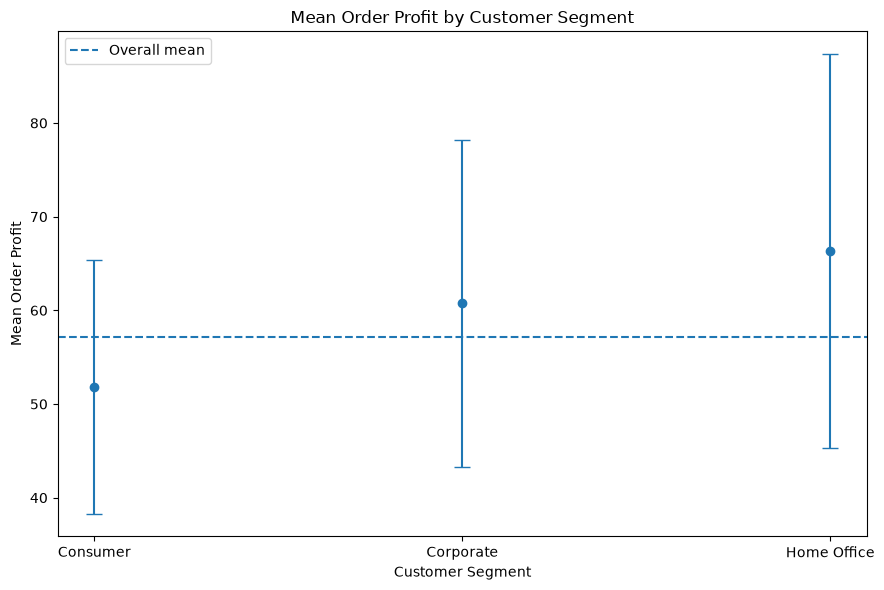

In [38]:
summary_plot = (
    order_data.groupby("Segment")["Order_Profit"]
    .agg(["mean", "count", "std"])
    .reset_index()
)

summary_plot["SE"] = summary_plot["std"] / np.sqrt(summary_plot["count"])

summary_plot["CI"] = summary_plot.apply(
    lambda row: stats.t.ppf(0.975, row["count"] - 1) * row["SE"],
    axis=1
)

plt.figure(figsize=(9, 6))

plt.errorbar(
    summary_plot["Segment"],
    summary_plot["mean"],
    yerr=summary_plot["CI"],
    fmt="o",
    capsize=6
)

plt.axhline(
    order_data["Order_Profit"].mean(),
    linestyle="--",
    label="Overall mean"
)

plt.title("Mean Order Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Mean Order Profit")
plt.legend()
plt.tight_layout()

plt.show()

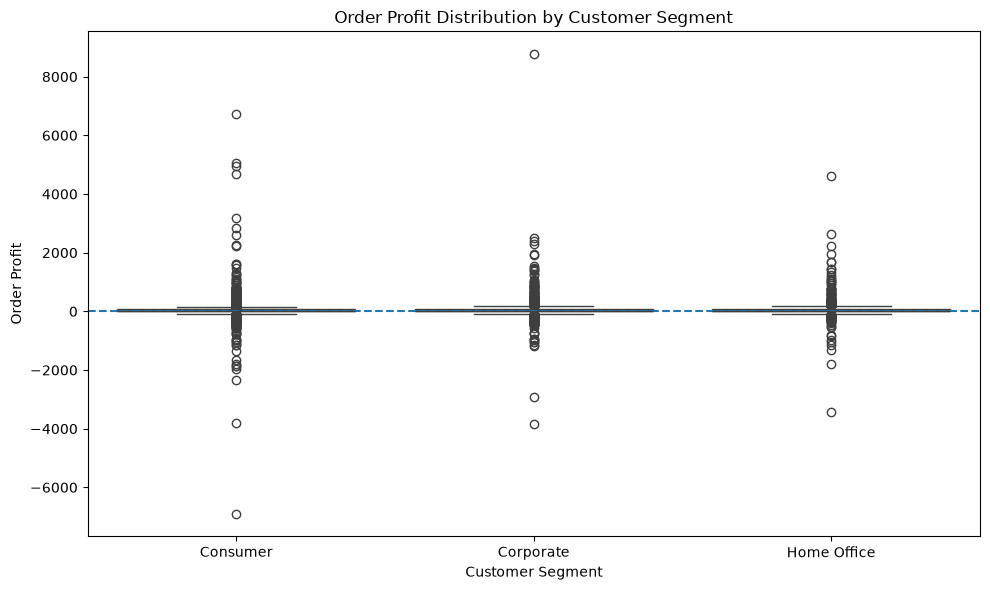

In [39]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=order_data,
    x="Segment",
    y="Order_Profit"
)

plt.axhline(0, linestyle="--")
plt.title("Order Profit Distribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Order Profit")
plt.tight_layout()

plt.savefig(
    "../visualizations/01_order_profit_distribution_by_segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

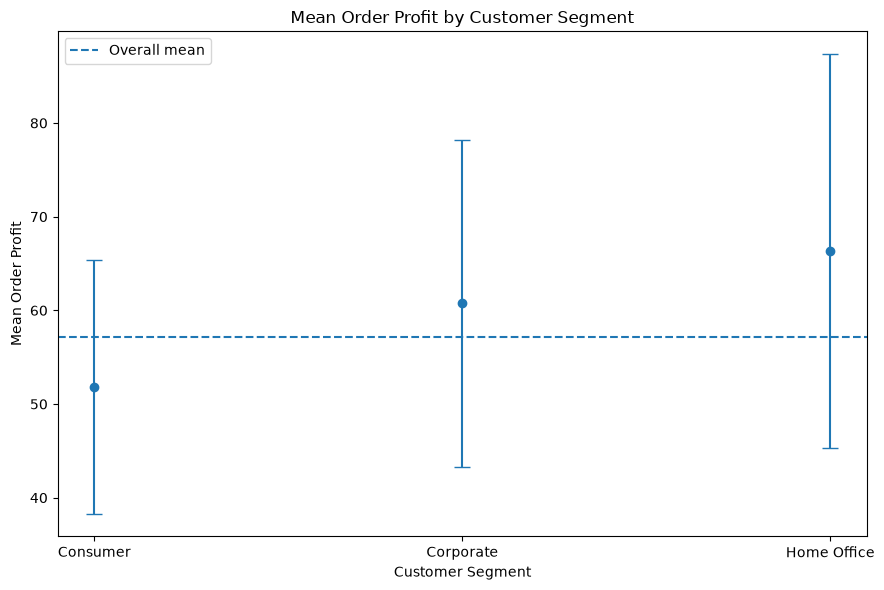

In [40]:
plt.figure(figsize=(9, 6))

plt.errorbar(
    summary_plot["Segment"],
    summary_plot["mean"],
    yerr=summary_plot["CI"],
    fmt="o",
    capsize=6
)

plt.axhline(
    order_data["Order_Profit"].mean(),
    linestyle="--",
    label="Overall mean"
)

plt.title("Mean Order Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Mean Order Profit")
plt.legend()
plt.tight_layout()

plt.savefig(
    "../visualizations/02_mean_order_profit_95ci.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

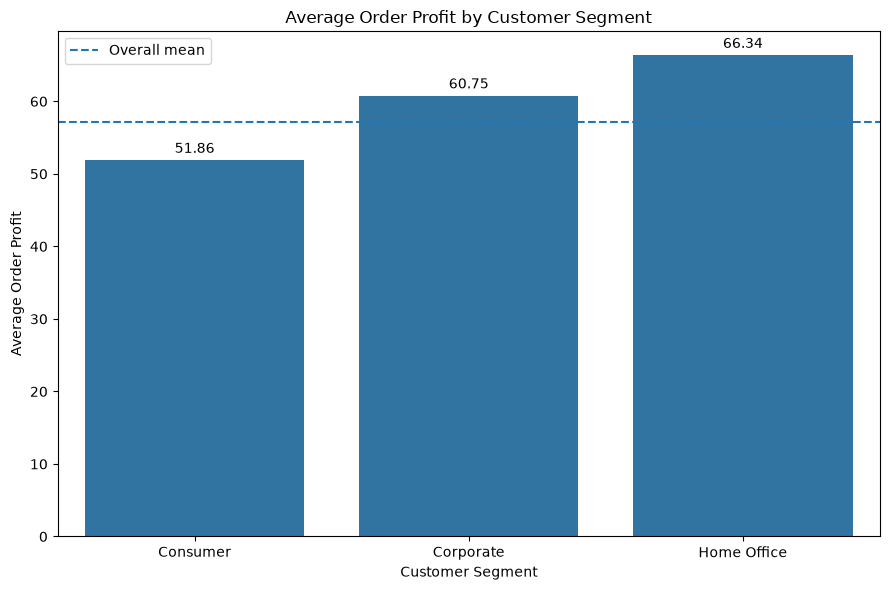

In [41]:
plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=summary_plot,
    x="Segment",
    y="mean"
)

plt.axhline(
    order_data["Order_Profit"].mean(),
    linestyle="--",
    label="Overall mean"
)

plt.title("Average Order Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Order Profit")
plt.legend()

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()

plt.savefig(
    "../visualizations/03_average_order_profit_by_segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

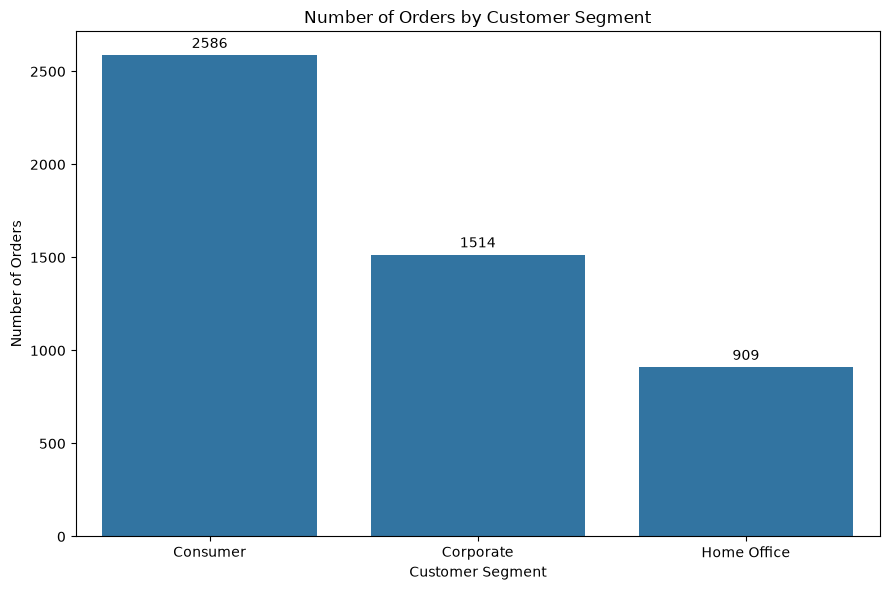

In [42]:
plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=summary_plot,
    x="Segment",
    y="count"
)

plt.title("Number of Orders by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Orders")

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()

plt.savefig(
    "../visualizations/04_order_count_by_segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [43]:
results_summary = pd.DataFrame({
    "Test": [
        "Levene's Test",
        "One-way ANOVA",
        "Kruskal-Wallis"
    ],
    "Statistic": [
        levene_stat,
        anova_stat,
        kruskal_stat
    ],
    "p_value": [
        levene_p,
        anova_p,
        kruskal_p
    ]
})

results_summary["p_value"] = results_summary["p_value"].round(4)
results_summary["Statistic"] = results_summary["Statistic"].round(4)

display(results_summary)

,Test,Statistic,p_value
0,Levene's Test,0.1695,0.8441
1,One-way ANOVA,0.7084,0.4925
2,Kruskal-Wallis,1.8403,0.3985


In [44]:
alpha = 0.05

if anova_p < alpha:
    anova_decision = "Reject H0"
else:
    anova_decision = "Fail to reject H0"

if kruskal_p < alpha:
    kruskal_decision = "Reject H0"
else:
    kruskal_decision = "Fail to reject H0"

print("Significance level (α):", alpha)
print("ANOVA decision:", anova_decision)
print("Kruskal-Wallis decision:", kruskal_decision)

print("\nFinal conclusion:")
print(
    "The analysis did not find statistically significant evidence "
    "that mean order profit differs among the three customer segments."
)

Significance level (α): 0.05
ANOVA decision: Fail to reject H0
Kruskal-Wallis decision: Fail to reject H0

Final conclusion:
The analysis did not find statistically significant evidence that mean order profit differs among the three customer segments.


## Conclusion

The objective of this analysis was to determine whether average order profit differs significantly among Consumer, Corporate, and Home Office customers.

The one-way ANOVA produced an F-statistic of 0.7084 with a p-value of 0.4925. Since the p-value is greater than the 0.05 significance level, the null hypothesis was not rejected.

Therefore, the analysis does not provide statistically significant evidence that average order profit differs among the three customer segments.

The Kruskal-Wallis robustness check produced a p-value of 0.3985 and reached the same overall conclusion.

Although the observed mean order profit was different across the groups, the effect size was very small (η² ≈ 0.0003), indicating that customer segment explained only a very small proportion of the variation in order profit.

### Practical Implications

The results suggest that customer segment alone may not be an important explanatory factor for differences in order-level profit in this dataset. Other variables such as discount, product category, region, sales volume, and product-level characteristics could potentially contribute more to profit variation.

These results describe an association in the analyzed dataset and should not be interpreted as evidence of a causal relationship.

### Limitations

- The analysis uses an observational dataset, so causal conclusions cannot be established.
- Order profit contains substantial skewness and extreme values.
- The dataset represents a specific Superstore sample and may not generalize to all businesses or customer populations.
- Customer segment was analyzed as the primary grouping variable; other potentially important explanatory variables were not included in the ANOVA.
- Aggregating transactions to the order level improves the unit of analysis, but orders may still share characteristics related to customers, products, regions, or time periods.

### Future Analysis

Future work could examine the effects of discount, product category, region, sales, and other variables using regression or other multivariable statistical methods.